# PapSmear-BD classification benchmark

Executed reference benchmark for the primary three-class and secondary five-class classification tasks using majority-class, HOG–RBF-SVM, ResNet18 and Swin-T baselines.


In [1]:
from __future__ import annotations

import hashlib
import json
import platform
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import skimage
import torch
import torch.nn as nn
import torchvision
from PIL import Image, ImageOps
from skimage.feature import hog
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid", context="notebook")

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("scikit-learn:", sklearn.__version__)
print("scikit-image:", skimage.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: 3.12.3
PyTorch: 2.5.1+cu121
torchvision: 0.20.1+cu121
scikit-learn: 1.9.0
scikit-image: 0.26.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4070 Ti SUPER


d:\razin\pap-smear-research\thesis_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
RUN_MODE = "publication"  # "publication" or "smoke_test"

FIVE_CLASSES = ["NILM", "ASCUS", "LSIL", "HSIL", "SCC"]
THREE_CLASSES = ["NILM", "LOW_GRADE", "HIGH_GRADE"]
FIVE_TO_THREE = {
    "NILM": "NILM",
    "ASCUS": "LOW_GRADE",
    "LSIL": "LOW_GRADE",
    "HSIL": "HIGH_GRADE",
    "SCC": "HIGH_GRADE",
}

@dataclass(frozen=True)
class Config:
    seed: int = 20260920
    folds: int = 5
    image_size: int = 224
    batch_size: int = 16
    num_workers: int = 0
    epochs: int = 20
    patience: int = 5
    learning_rate: float = 2e-4
    weight_decay: float = 1e-4
    validation_fraction: float = 0.15
    bootstrap_replicates: int = 2000
    tasks: tuple[str, ...] = ("three_class", "five_class")
    deep_models: tuple[str, ...] = ("resnet18", "swin_t")
    run_svm: bool = True
    pretrained: bool = True

CONFIG = Config()
if RUN_MODE == "smoke_test":
    CONFIG = Config(
        folds=3,
        image_size=160,
        batch_size=8,
        epochs=1,
        patience=1,
        bootstrap_replicates=100,
        tasks=("three_class",),
        deep_models=("resnet18",),
        run_svm=False,
        pretrained=False,
    )

def find_project_root(start: str | Path = ".") -> Path:
    current = Path(start).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "PapSmear-BD_Zenodo_v1.0.0" / "metadata.csv").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find PapSmear-BD_Zenodo_v1.0.0/metadata.csv. Place the extracted dataset beside this repository."
    )

PROJECT_ROOT = find_project_root()
DATASET_ROOT = PROJECT_ROOT / "PapSmear-BD_Zenodo_v1.0.0"
OUTPUT_ROOT = PROJECT_ROOT / "results" / "paper_a_publication_benchmark" / RUN_MODE
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_ROOT)
print("Outputs:", OUTPUT_ROOT)
print("Device:", DEVICE)
print(CONFIG)


Project: D:\razin\pap-smear-research
Dataset: D:\razin\pap-smear-research\PapSmear-BD_v1
Outputs: D:\razin\pap-smear-research\results\paper_a_publication_benchmark\publication
Device: cuda
Config(seed=20260920, folds=5, image_size=224, batch_size=16, num_workers=0, epochs=20, patience=5, learning_rate=0.0002, weight_decay=0.0001, validation_fraction=0.15, bootstrap_replicates=2000, tasks=('three_class', 'five_class'), deep_models=('resnet18', 'swin_t'), run_svm=True, pretrained=True)


In [ ]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def load_manifest(dataset_root: Path) -> pd.DataFrame:
    manifest_path = dataset_root / "metadata.csv"
    frame = pd.read_csv(manifest_path)
    required = {
        "image_filename",
        "relative_path",
        "classification",
        "sha256",
    }
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"metadata.csv is missing required columns: {sorted(missing)}")

    frame = frame.rename(columns={"image_filename": "image_name"}).copy()
    frame["classification"] = frame["classification"].astype(str).str.upper().str.strip()
    invalid = sorted(set(frame["classification"]) - set(FIVE_CLASSES))
    if invalid:
        raise ValueError(f"Unsupported classes: {invalid}")
    duplicates = frame[frame.image_name.str.casefold().duplicated(keep=False)]
    if len(duplicates):
        raise ValueError(f"Duplicate manifest filenames: {duplicates.image_name.tolist()[:10]}")

    frame["label_5"] = frame.classification
    frame["label_3"] = frame.classification.map(FIVE_TO_THREE)
    relative = frame.relative_path.astype(str).map(Path)
    if any(path.is_absolute() or ".." in path.parts for path in relative):
        raise ValueError("metadata.csv contains an unsafe relative_path")
    frame["image_path"] = [str(dataset_root / path) for path in relative]
    return frame.sort_values("image_name").reset_index(drop=True)


manifest = load_manifest(DATASET_ROOT)
if RUN_MODE == "smoke_test":
    manifest = manifest.groupby("classification", group_keys=False).head(24).reset_index(drop=True)

records = []
for row in tqdm(manifest.itertuples(index=False), total=len(manifest), desc="Checking images"):
    path = Path(row.image_path)
    status = {
        "image_name": row.image_name,
        "exists": path.is_file(),
        "readable": False,
        "width": None,
        "height": None,
        "mode": None,
    }
    if path.is_file():
        try:
            with Image.open(path) as image:
                image.verify()
            with Image.open(path) as image:
                status.update(readable=True, width=image.width, height=image.height, mode=image.mode)
        except Exception:
            pass
    records.append(status)

technical_audit = pd.DataFrame(records)
technical_audit.to_csv(OUTPUT_ROOT / "technical_preflight.csv", index=False)
bad = technical_audit[~technical_audit.exists | ~technical_audit.readable]
if len(bad):
    raise RuntimeError(f"{len(bad)} images are missing or unreadable. Inspect technical_preflight.csv")

print("Images:", len(manifest))
display(manifest.classification.value_counts().reindex(FIVE_CLASSES).rename("count").to_frame())



classification,NILM,ASCUS,LSIL,HSIL,SCC,total
outer_fold,,,,,,
0,180,53,38,51,129,451
1,180,53,39,50,129,451
2,181,52,38,51,129,451
3,180,52,38,51,129,450
4,180,52,38,51,129,450


Split SHA-256: 585b5bf7434eeac707522520c420dcc4ad6b4fabc71f6edcef5bfe8c86fd2bc8


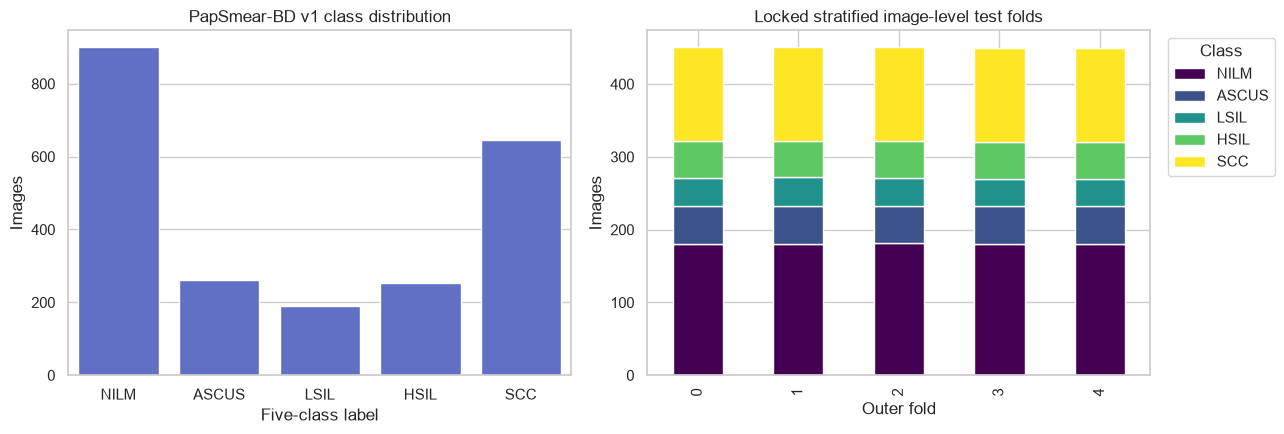

In [4]:
splitter = StratifiedKFold(n_splits=CONFIG.folds, shuffle=True, random_state=CONFIG.seed)
manifest["outer_fold"] = -1
for fold, (_, test_pos) in enumerate(splitter.split(manifest, manifest.classification)):
    manifest.loc[test_pos, "outer_fold"] = fold
manifest["outer_fold"] = manifest.outer_fold.astype(int)

assert (manifest.outer_fold >= 0).all()
assert manifest.image_name.nunique() == len(manifest)
fold_counts = pd.crosstab(manifest.outer_fold, manifest.classification).reindex(columns=FIVE_CLASSES, fill_value=0)
assert (fold_counts > 0).all().all(), "Each fold must contain all five classes"

split_columns = ["image_name", "classification", "label_3", "outer_fold"]
split_path = OUTPUT_ROOT / "locked_stratified_split_manifest.csv"
manifest[split_columns].to_csv(split_path, index=False)
split_hash = sha256_file(split_path)
(OUTPUT_ROOT / "locked_stratified_split_manifest.sha256.txt").write_text(
    f"{split_hash}  {split_path.name}\n", encoding="utf-8"
)

display(fold_counts.assign(total=fold_counts.sum(axis=1)))
print("Split SHA-256:", split_hash)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=manifest, x="classification", order=FIVE_CLASSES, ax=axes[0], color="#5065d6")
axes[0].set(title="PapSmear-BD v1 class distribution", xlabel="Five-class label", ylabel="Images")
fold_counts.plot(kind="bar", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set(title="Locked stratified image-level test folds", xlabel="Outer fold", ylabel="Images")
axes[1].legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "Figure_1_dataset_and_fold_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [5]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def pad_to_square(image: Image.Image) -> Image.Image:
    side = max(image.size)
    return ImageOps.pad(image, (side, side), color=(245, 245, 245), centering=(0.5, 0.5))

normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_transform = transforms.Compose([
    transforms.Lambda(pad_to_square),
    transforms.Resize((CONFIG.image_size, CONFIG.image_size), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15, fill=(245, 245, 245)),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.05, hue=0.01),
    transforms.ToTensor(),
    normalize,
])
eval_transform = transforms.Compose([
    transforms.Lambda(pad_to_square),
    transforms.Resize((CONFIG.image_size, CONFIG.image_size), antialias=True),
    transforms.ToTensor(),
    normalize,
])

class ImageDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, task: str, transform):
        self.frame = frame.reset_index(drop=True)
        self.task = task
        self.transform = transform
        self.classes = THREE_CLASSES if task == "three_class" else FIVE_CLASSES
        self.class_to_index = {name: index for index, name in enumerate(self.classes)}

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index: int):
        row = self.frame.iloc[index]
        label = row.label_3 if self.task == "three_class" else row.label_5
        with Image.open(row.image_path) as image:
            tensor = self.transform(image.convert("RGB"))
        return tensor, self.class_to_index[label], row.image_name

def make_model(name: str, num_classes: int, pretrained: bool = True) -> nn.Module:
    if name == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif name == "swin_t":
        weights = models.Swin_T_Weights.DEFAULT if pretrained else None
        model = models.swin_t(weights=weights)
        model.head = nn.Linear(model.head.in_features, num_classes)
    else:
        raise ValueError(name)
    return model

def choose_inner_validation(frame: pd.DataFrame, task: str, seed: int, fraction: float) -> tuple[np.ndarray, np.ndarray]:
    label_col = "label_3" if task == "three_class" else "label_5"
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=fraction, random_state=seed)
    train_pos, val_pos = next(splitter.split(frame, frame[label_col]))
    return train_pos, val_pos

def class_weights(frame: pd.DataFrame, task: str) -> torch.Tensor:
    label_col = "label_3" if task == "three_class" else "label_5"
    classes = THREE_CLASSES if task == "three_class" else FIVE_CLASSES
    counts = frame[label_col].value_counts().reindex(classes).to_numpy(dtype=float)
    weights = len(frame) / (len(classes) * counts)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


In [6]:
def make_loader(frame: pd.DataFrame, task: str, training: bool) -> DataLoader:
    dataset = ImageDataset(frame, task, train_transform if training else eval_transform)
    generator = torch.Generator().manual_seed(CONFIG.seed)
    return DataLoader(
        dataset,
        batch_size=CONFIG.batch_size,
        shuffle=training,
        num_workers=CONFIG.num_workers,
        pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(CONFIG.num_workers > 0),
        generator=generator,
    )

@torch.no_grad()
def predict_deep(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, np.ndarray, list[str]]:
    model.eval()
    probabilities, labels, names = [], [], []
    for images, targets, batch_names in loader:
        logits = model(images.to(DEVICE, non_blocking=True))
        probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
        labels.append(targets.numpy())
        names.extend(batch_names)
    return np.concatenate(probabilities), np.concatenate(labels), names

def make_run_signature(task: str, model_name: str, fold: int) -> str:
    payload = json.dumps(
        {"config": asdict(CONFIG), "split_sha256": split_hash, "task": task, "model": model_name, "fold": fold},
        sort_keys=True,
    )
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()

def completed_or_conflicting_run(run_dir: Path, signature: str) -> pd.DataFrame | None:
    prediction_path = run_dir / "test_predictions.csv"
    signature_path = run_dir / "run_signature.txt"
    if prediction_path.is_file() and signature_path.is_file():
        if signature_path.read_text(encoding="utf-8").strip() == signature:
            return pd.read_csv(prediction_path)
        raise RuntimeError(f"Existing results use a different configuration: {run_dir}")
    if prediction_path.is_file() or signature_path.is_file():
        raise RuntimeError(f"Incomplete or unsigned prior result found: {run_dir}")
    return None

def train_deep_fold(model_name: str, task: str, fold: int) -> pd.DataFrame:
    classes = THREE_CLASSES if task == "three_class" else FIVE_CLASSES
    run_dir = OUTPUT_ROOT / "runs" / task / model_name / f"fold_{fold}"
    run_dir.mkdir(parents=True, exist_ok=True)
    prediction_path = run_dir / "test_predictions.csv"
    signature_path = run_dir / "run_signature.txt"
    signature = make_run_signature(task, model_name, fold)
    completed = completed_or_conflicting_run(run_dir, signature)
    if completed is not None:
        print(f"Reuse completed: {task} / {model_name} / fold {fold}")
        return completed

    outer_train = manifest[manifest.outer_fold != fold].copy()
    outer_test = manifest[manifest.outer_fold == fold].copy()
    train_pos, val_pos = choose_inner_validation(
        outer_train, task, CONFIG.seed + fold, CONFIG.validation_fraction
    )
    train_frame = outer_train.iloc[train_pos].copy()
    val_frame = outer_train.iloc[val_pos].copy()
    assert set(train_frame.index).isdisjoint(val_frame.index)
    assert set(outer_train.image_name).isdisjoint(outer_test.image_name)

    seed_everything(CONFIG.seed + fold)
    model = make_model(model_name, len(classes), CONFIG.pretrained).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights(train_frame, task))
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG.learning_rate, weight_decay=CONFIG.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(CONFIG.epochs, 1))
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    train_loader = make_loader(train_frame, task, True)
    val_loader = make_loader(val_frame, task, False)
    test_loader = make_loader(outer_test, task, False)

    best_score, stale = -np.inf, 0
    history = []
    checkpoint_path = run_dir / "best_model.pt"
    for epoch in range(1, CONFIG.epochs + 1):
        model.train()
        running_loss, seen = 0.0, 0
        for images, targets, _ in tqdm(train_loader, desc=f"{task} {model_name} F{fold} E{epoch}", leave=False):
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, targets)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += float(loss.detach()) * len(targets)
            seen += len(targets)
        scheduler.step()

        val_prob, val_true, _ = predict_deep(model, val_loader)
        val_pred = val_prob.argmax(axis=1)
        val_balanced_accuracy = balanced_accuracy_score(val_true, val_pred)
        history.append({
            "epoch": epoch,
            "train_loss": running_loss / max(seen, 1),
            "validation_balanced_accuracy": val_balanced_accuracy,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        print(f"{task} {model_name} fold {fold}: epoch {epoch:02d}, val BA={val_balanced_accuracy:.4f}")
        if val_balanced_accuracy > best_score + 1e-5:
            best_score, stale = val_balanced_accuracy, 0
            torch.save({"state_dict": model.state_dict(), "classes": classes, "config": asdict(CONFIG)}, checkpoint_path)
        else:
            stale += 1
            if stale >= CONFIG.patience:
                print("Early stopping")
                break

    pd.DataFrame(history).to_csv(run_dir / "training_history.csv", index=False)
    state = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(state["state_dict"])
    test_prob, test_true, test_names = predict_deep(model, test_loader)
    rows = pd.DataFrame({"image_name": test_names, "y_true": test_true, "y_pred": test_prob.argmax(axis=1)})
    for index, name in enumerate(classes):
        rows[f"prob_{name}"] = test_prob[:, index]
    rows["task"] = task
    rows["model"] = model_name
    rows["outer_fold"] = fold
    rows.to_csv(prediction_path, index=False)
    signature_path.write_text(signature + "\n", encoding="utf-8")
    return rows


In [7]:
def majority_baseline_fold(task: str, fold: int) -> pd.DataFrame:
    classes = THREE_CLASSES if task == "three_class" else FIVE_CLASSES
    label_col = "label_3" if task == "three_class" else "label_5"
    class_to_index = {name: index for index, name in enumerate(classes)}
    run_dir = OUTPUT_ROOT / "runs" / task / "majority_class" / f"fold_{fold}"
    run_dir.mkdir(parents=True, exist_ok=True)
    prediction_path = run_dir / "test_predictions.csv"
    signature_path = run_dir / "run_signature.txt"
    signature = make_run_signature(task, "majority_class", fold)
    completed = completed_or_conflicting_run(run_dir, signature)
    if completed is not None:
        print(f"Reuse completed: {task} / majority class / fold {fold}")
        return completed

    train_mask = manifest.outer_fold.to_numpy() != fold
    test_mask = ~train_mask
    y_train = manifest.loc[train_mask, label_col].map(class_to_index).to_numpy()
    y_test = manifest.loc[test_mask, label_col].map(class_to_index).to_numpy()
    counts = np.bincount(y_train, minlength=len(classes)).astype(float)
    training_priors = counts / counts.sum()
    probabilities = np.tile(training_priors, (test_mask.sum(), 1))
    rows = pd.DataFrame({
        "image_name": manifest.loc[test_mask, "image_name"].to_numpy(),
        "y_true": y_test,
        "y_pred": probabilities.argmax(axis=1),
    })
    for index, name in enumerate(classes):
        rows[f"prob_{name}"] = probabilities[:, index]
    rows["task"] = task
    rows["model"] = "majority_class"
    rows["outer_fold"] = fold
    rows.to_csv(prediction_path, index=False)
    signature_path.write_text(signature + "\n", encoding="utf-8")
    return rows

def extract_hog_colour_features(frame: pd.DataFrame) -> np.ndarray:
    cache_path = OUTPUT_ROOT / "hog_colour_features.npz"
    ordered_names = frame.image_name.tolist()
    if cache_path.is_file():
        cached = np.load(cache_path, allow_pickle=True)
        if cached["image_name"].tolist() == ordered_names:
            return cached["features"]

    features = []
    for row in tqdm(frame.itertuples(index=False), total=len(frame), desc="HOG + colour features"):
        with Image.open(row.image_path) as image:
            image = pad_to_square(image.convert("RGB")).resize((224, 224), Image.Resampling.BILINEAR)
            array = np.asarray(image, dtype=np.float32) / 255.0
        hog_vector = hog(
            array,
            orientations=9,
            pixels_per_cell=(16, 16),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            channel_axis=-1,
            feature_vector=True,
        )
        histograms = [np.histogram(array[..., channel], bins=16, range=(0, 1), density=True)[0] for channel in range(3)]
        features.append(np.concatenate([hog_vector, *histograms]).astype(np.float32))
    matrix = np.stack(features)
    np.savez_compressed(cache_path, image_name=np.asarray(ordered_names), features=matrix)
    return matrix

def train_svm_fold(features: np.ndarray, task: str, fold: int) -> pd.DataFrame:
    classes = THREE_CLASSES if task == "three_class" else FIVE_CLASSES
    label_col = "label_3" if task == "three_class" else "label_5"
    class_to_index = {name: index for index, name in enumerate(classes)}
    run_dir = OUTPUT_ROOT / "runs" / task / "hog_rbf_svm" / f"fold_{fold}"
    run_dir.mkdir(parents=True, exist_ok=True)
    prediction_path = run_dir / "test_predictions.csv"
    signature_path = run_dir / "run_signature.txt"
    signature = make_run_signature(task, "hog_rbf_svm", fold)
    completed = completed_or_conflicting_run(run_dir, signature)
    if completed is not None:
        print(f"Reuse completed: {task} / HOG-RBF-SVM / fold {fold}")
        return completed

    train_mask = manifest.outer_fold.to_numpy() != fold
    test_mask = ~train_mask
    y_train = manifest.loc[train_mask, label_col].map(class_to_index).to_numpy()
    y_test = manifest.loc[test_mask, label_col].map(class_to_index).to_numpy()
    classifier = Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(C=4.0, kernel="rbf", gamma="scale", class_weight="balanced", probability=True, random_state=CONFIG.seed + fold)),
    ])
    classifier.fit(features[train_mask], y_train)
    raw_prob = classifier.predict_proba(features[test_mask])
    probabilities = np.zeros((test_mask.sum(), len(classes)), dtype=float)
    probabilities[:, classifier.named_steps["svm"].classes_.astype(int)] = raw_prob
    rows = pd.DataFrame({
        "image_name": manifest.loc[test_mask, "image_name"].to_numpy(),
        "y_true": y_test,
        "y_pred": probabilities.argmax(axis=1),
    })
    for index, name in enumerate(classes):
        rows[f"prob_{name}"] = probabilities[:, index]
    rows["task"] = task
    rows["model"] = "hog_rbf_svm"
    rows["outer_fold"] = fold
    rows.to_csv(prediction_path, index=False)
    signature_path.write_text(signature + "\n", encoding="utf-8")
    return rows


In [8]:
all_predictions = []

for task in CONFIG.tasks:
    for fold in range(CONFIG.folds):
        all_predictions.append(majority_baseline_fold(task, fold))

if CONFIG.run_svm:
    hog_features = extract_hog_colour_features(manifest)
    for task in CONFIG.tasks:
        for fold in range(CONFIG.folds):
            all_predictions.append(train_svm_fold(hog_features, task, fold))

for task in CONFIG.tasks:
    for model_name in CONFIG.deep_models:
        for fold in range(CONFIG.folds):
            all_predictions.append(train_deep_fold(model_name, task, fold))

predictions = pd.concat(all_predictions, ignore_index=True)
predictions = predictions.merge(
    manifest[["image_name", "classification", "label_3", "label_5"]],
    on="image_name",
    how="left",
    validate="many_to_one",
)
predictions.to_csv(OUTPUT_ROOT / "all_out_of_fold_predictions.csv", index=False)

expected_models = ["majority_class"] + (["hog_rbf_svm"] if CONFIG.run_svm else []) + list(CONFIG.deep_models)
for task in CONFIG.tasks:
    for model_name in expected_models:
        subset = predictions[(predictions.task == task) & (predictions.model == model_name)]
        assert subset.image_name.nunique() == len(manifest), f"Incomplete OOF coverage: {task}/{model_name}"
        assert not subset.image_name.duplicated().any(), f"Duplicate OOF predictions: {task}/{model_name}"

print("Completed OOF prediction rows:", len(predictions))
display(predictions.groupby(["task", "model"]).image_name.nunique().rename("OOF images").to_frame())


HOG + colour features: 100%|██████████| 2253/2253 [03:34<00:00, 10.51it/s]
d:\razin\pap-smear-research\thesis_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\razin\pap-smear-research\thesis_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\razin\pap-smear-research\thesis_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\razin\pap-smear-research\thesis_env\Lib\site-packages\s

three_class resnet18 fold 0: epoch 01, val BA=0.7271


three_class resnet18 fold 0: epoch 02, val BA=0.7477


three_class resnet18 fold 0: epoch 03, val BA=0.7722


three_class resnet18 fold 0: epoch 04, val BA=0.8341


...

five_class swin_t fold 4: epoch 17, val BA=0.6537


five_class swin_t fold 4: epoch 18, val BA=0.6754


five_class swin_t fold 4: epoch 19, val BA=0.6668


five_class swin_t fold 4: epoch 20, val BA=0.6686
Completed OOF prediction rows: 18024


OOF images
task        model                     
five_class  hog_rbf_svm           2253
            majority_class        2253
            resnet18              2253
            swin_t                2253
three_class hog_rbf_svm           2253
            majority_class        2253
            resnet18              2253
            swin_t                2253

In [9]:
def normalize_probability_rows(probabilities: np.ndarray) -> np.ndarray:
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.ndim != 2:
        raise ValueError("Probability matrix must be two-dimensional.")
    if not np.all(np.isfinite(probabilities)):
        raise ValueError("Probability matrix contains non-finite values.")
    if np.any(probabilities < 0):
        raise ValueError("Probability matrix contains negative values.")
    row_sums = probabilities.sum(axis=1, keepdims=True)
    if np.any(row_sums <= 0):
        raise ValueError("Probability rows must have positive sums.")
    return probabilities / row_sums

def metric_values(y_true: np.ndarray, probabilities: np.ndarray, n_classes: int) -> dict[str, float]:
    probabilities = normalize_probability_rows(probabilities)
    y_pred = probabilities.argmax(axis=1)
    one_hot = label_binarize(y_true, classes=np.arange(n_classes))
    if n_classes == 2 and one_hot.shape[1] == 1:
        one_hot = np.column_stack([1 - one_hot[:, 0], one_hot[:, 0]])
    result = {
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "log_loss": log_loss(y_true, probabilities, labels=np.arange(n_classes)),
    }
    try:
        result["macro_roc_auc_ovr"] = roc_auc_score(one_hot, probabilities, average="macro", multi_class="ovr")
        result["macro_average_precision"] = average_precision_score(one_hot, probabilities, average="macro")
    except ValueError:
        result["macro_roc_auc_ovr"] = np.nan
        result["macro_average_precision"] = np.nan
    return result

def stratified_bootstrap_indices(y_true: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    class_indices = [np.flatnonzero(y_true == class_index) for class_index in np.unique(y_true)]
    return np.concatenate([
        rng.choice(indices, size=len(indices), replace=True) for indices in class_indices
    ])

def stratified_bootstrap_metrics(frame: pd.DataFrame, classes: list[str], repeats: int, seed: int) -> pd.DataFrame:
    probability_columns = [f"prob_{name}" for name in classes]
    y_true = frame.y_true.to_numpy()
    probabilities = frame[probability_columns].to_numpy()
    rng = np.random.default_rng(seed)
    rows = []
    for replicate in range(repeats):
        sampled_indices = stratified_bootstrap_indices(y_true, rng)
        values = metric_values(y_true[sampled_indices], probabilities[sampled_indices], len(classes))
        values["replicate"] = replicate
        rows.append(values)
    return pd.DataFrame(rows)

summary_rows, per_class_rows, fold_rows = [], [], []
bootstrap_store = {}
cohorts = {"full_release": lambda x: x}

for (task, model_name), model_frame in predictions.groupby(["task", "model"], sort=True):
    classes = THREE_CLASSES if task == "three_class" else FIVE_CLASSES
    probability_columns = [f"prob_{name}" for name in classes]
    for cohort_name, select in cohorts.items():
        cohort = select(model_frame).copy().reset_index(drop=True)
        point = metric_values(cohort.y_true.to_numpy(), cohort[probability_columns].to_numpy(), len(classes))
        boot = stratified_bootstrap_metrics(cohort, classes, CONFIG.bootstrap_replicates, CONFIG.seed)
        bootstrap_store[(task, model_name, cohort_name)] = boot
        for metric, value in point.items():
            valid = boot[metric].dropna() if metric in boot else pd.Series(dtype=float)
            summary_rows.append({
                "task": task,
                "model": model_name,
                "cohort": cohort_name,
                "metric": metric,
                "estimate": value,
                "ci95_low": valid.quantile(0.025) if len(valid) else np.nan,
                "ci95_high": valid.quantile(0.975) if len(valid) else np.nan,
                "n_images": len(cohort),
                "bootstrap_unit": "image_stratified_by_true_class",
                "bootstrap_replicates_used": len(valid),
            })

        y_true, y_pred = cohort.y_true.to_numpy(), cohort.y_pred.to_numpy()
        precision, recall, f1, support = precision_recall_fscore_support(
            y_true, y_pred, labels=np.arange(len(classes)), zero_division=0
        )
        cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(classes)))
        for index, class_name in enumerate(classes):
            tn = cm.sum() - cm[index, :].sum() - cm[:, index].sum() + cm[index, index]
            fp = cm[:, index].sum() - cm[index, index]
            per_class_rows.append({
                "task": task, "model": model_name, "cohort": cohort_name, "class": class_name,
                "precision": precision[index], "recall_sensitivity": recall[index], "f1": f1[index],
                "specificity": tn / (tn + fp) if tn + fp else np.nan, "support": int(support[index]),
            })

    for fold, fold_frame in model_frame.groupby("outer_fold"):
        values = metric_values(
            fold_frame.y_true.to_numpy(), fold_frame[probability_columns].to_numpy(), len(classes)
        )
        for metric, value in values.items():
            fold_rows.append({
                "task": task,
                "model": model_name,
                "outer_fold": int(fold),
                "metric": metric,
                "value": value,
                "n_images": len(fold_frame),
            })

summary_metrics = pd.DataFrame(summary_rows)
per_class_metrics = pd.DataFrame(per_class_rows)
fold_metrics = pd.DataFrame(fold_rows)
summary_metrics.to_csv(OUTPUT_ROOT / "summary_metrics_with_stratified_image_bootstrap_ci.csv", index=False)
per_class_metrics.to_csv(OUTPUT_ROOT / "per_class_metrics.csv", index=False)
fold_metrics.to_csv(OUTPUT_ROOT / "fold_metrics.csv", index=False)

primary = summary_metrics.query("cohort == 'full_release' and metric in ['balanced_accuracy', 'macro_f1', 'accuracy']")
display(primary.pivot_table(index=["task", "model"], columns="metric", values=["estimate", "ci95_low", "ci95_high"]).round(4))


ci95_high                            ci95_low  \
metric                      accuracy balanced_accuracy macro_f1 accuracy   
task        model                                                          
five_class  hog_rbf_svm       0.6534            0.4767   0.4854   0.6205   
            majority_class    0.3999            0.2000   0.1143   0.3999   
            resnet18          0.7732            0.6724   0.6656   0.7417   
            swin_t            0.7759            0.6967   0.6811   0.7426   
three_class hog_rbf_svm       0.7395            0.6799   0.6818   0.7062   
            majority_class    0.3999            0.3333   0.1904   0.3999   
            resnet18          0.8575            0.8351   0.8305   0.8287   
            swin_t            0.8642            0.8578   0.8442   0.8344   

                                                      estimate  \
metric                     balanced_accuracy macro_f1 accuracy   
task        model                                                
five_class  hog_rbf_svm               0.4371   0.4390   0.6369   
            majority_class            0.2000   0.1143   0.3999   
            resnet18                  0.6266   0.6213   0.7577   
            swin_t                    0.6493   0.6368   0.7594   
three_class hog_rbf_svm               0.6415   0.6404   0.7226   
            majority_class            0.3333   0.1904   0.3999   
            resnet18                  0.8014   0.7972   0.8433   
            swin_t                    0.8260   0.8134   0.8491   

                                                       
metric                     balanced_accuracy macro_f1  
task        model                                      
five_class  hog_rbf_svm               0.4561   0.4614  
            majority_class            0.2000   0.1143  
            resnet18                  0.6496   0.6434  
            swin_t                    0.6733   0.6596  
three_class hog_rbf_svm               0.6607   0.6613  
            majority_class            0.3333   0.1904  
            resnet18                  0.8181   0.8140  
            swin_t                    0.8419   0.8284

In [10]:
# Paired stratified image bootstrap differences between models.
comparison_rows = []
models_present = sorted(predictions.model.unique())
for task in CONFIG.tasks:
    classes = THREE_CLASSES if task == "three_class" else FIVE_CLASSES
    probability_columns = [f"prob_{name}" for name in classes]
    task_frames = {
        model_name: predictions.query("task == @task and model == @model_name").set_index("image_name").sort_index()
        for model_name in models_present
    }
    common_names = sorted(set.intersection(*(set(frame.index) for frame in task_frames.values())))
    rng = np.random.default_rng(CONFIG.seed + 991)
    for left_index, left in enumerate(models_present):
        for right in models_present[left_index + 1:]:
            left_frame = task_frames[left].loc[common_names]
            right_frame = task_frames[right].loc[common_names]
            y_true = left_frame.y_true.to_numpy()
            assert np.array_equal(y_true, right_frame.y_true.to_numpy())
            left_probabilities = left_frame[probability_columns].to_numpy()
            right_probabilities = right_frame[probability_columns].to_numpy()
            differences = {"balanced_accuracy": [], "macro_f1": []}
            for _ in range(CONFIG.bootstrap_replicates):
                sampled_indices = stratified_bootstrap_indices(y_true, rng)
                left_metrics = metric_values(y_true[sampled_indices], left_probabilities[sampled_indices], len(classes))
                right_metrics = metric_values(y_true[sampled_indices], right_probabilities[sampled_indices], len(classes))
                for metric in differences:
                    differences[metric].append(left_metrics[metric] - right_metrics[metric])
            left_point = metric_values(y_true, left_probabilities, len(classes))
            right_point = metric_values(y_true, right_probabilities, len(classes))
            for metric, values in differences.items():
                values = np.asarray(values)
                comparison_rows.append({
                    "task": task, "model_a": left, "model_b": right, "metric": metric,
                    "difference_a_minus_b": left_point[metric] - right_point[metric],
                    "ci95_low": np.quantile(values, 0.025), "ci95_high": np.quantile(values, 0.975),
                    "two_sided_bootstrap_p": min(
                        1.0,
                        2 * min(
                            (np.count_nonzero(values <= 0) + 1) / (len(values) + 1),
                            (np.count_nonzero(values >= 0) + 1) / (len(values) + 1),
                        ),
                    ),
                    "bootstrap_replicates_used": len(values),
                })

paired_comparisons = pd.DataFrame(comparison_rows)
if len(paired_comparisons):
    raw_p = paired_comparisons.two_sided_bootstrap_p.clip(upper=1).to_numpy()
    order = np.argsort(raw_p)
    adjusted_ordered = np.maximum.accumulate(
        np.minimum(1.0, raw_p[order] * (len(raw_p) - np.arange(len(raw_p))))
    )
    adjusted = np.empty_like(adjusted_ordered)
    adjusted[order] = adjusted_ordered
    paired_comparisons["holm_adjusted_p"] = adjusted
paired_comparisons.to_csv(OUTPUT_ROOT / "paired_stratified_image_bootstrap_comparisons.csv", index=False)
display(paired_comparisons.round(4))


,task,model_a,model_b,metric,difference_a_minus_b,ci95_low,ci95_high,two_sided_bootstrap_p,bootstrap_replicates_used,holm_adjusted_p
0,three_class,hog_rbf_svm,majority_class,balanced_accuracy,0.3274,0.3089,0.3472,0.0010,2000,0.0240
1,three_class,hog_rbf_svm,majority_class,macro_f1,0.4709,0.4511,0.4921,0.0010,2000,0.0240
2,three_class,hog_rbf_svm,resnet18,balanced_accuracy,-0.1574,-0.1814,-0.1341,0.0010,2000,0.0240
3,three_class,hog_rbf_svm,resnet18,macro_f1,-0.1526,-0.1767,-0.1288,0.0010,2000,0.0240
4,three_class,hog_rbf_svm,swin_t,balanced_accuracy,-0.1812,-0.2023,-0.1594,0.0010,2000,0.0240
5,three_class,hog_rbf_svm,swin_t,macro_f1,-0.1670,-0.1895,-0.1445,0.0010,2000,0.0240
6,three_class,majority_class,resnet18,balanced_accuracy,-0.4847,-0.5017,-0.4682,0.0010,2000,0.0240
7,three_class,majority_class,resnet18,macro_f1,-0.6235,-0.6399,-0.6073,0.0010,2000,0.0240
8,three_class,majority_class,swin_t,balanced_accuracy,-0.5086,-0.5241,-0.4923,0.0010,2000,0.0240
9,three_class,majority_class,swin_t,macro_f1,-0.6379,-0.6529,-0.6224,0.0010,2000,0.0240


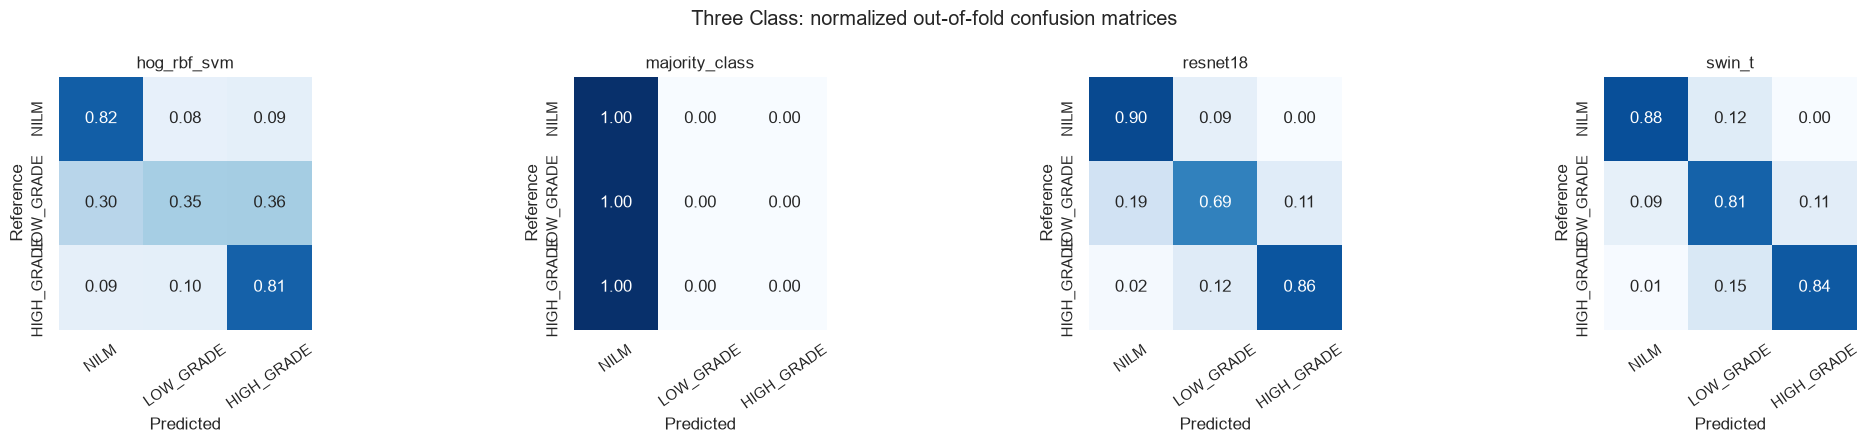

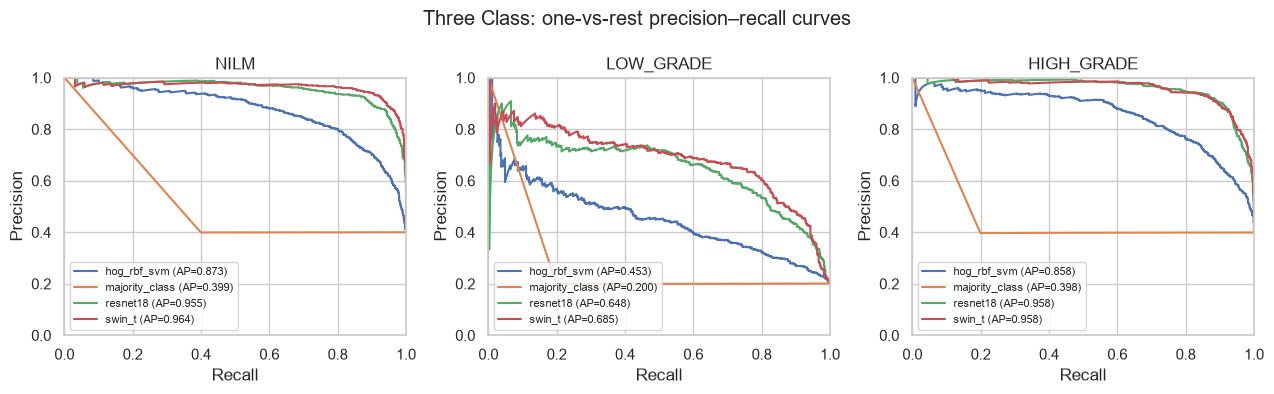

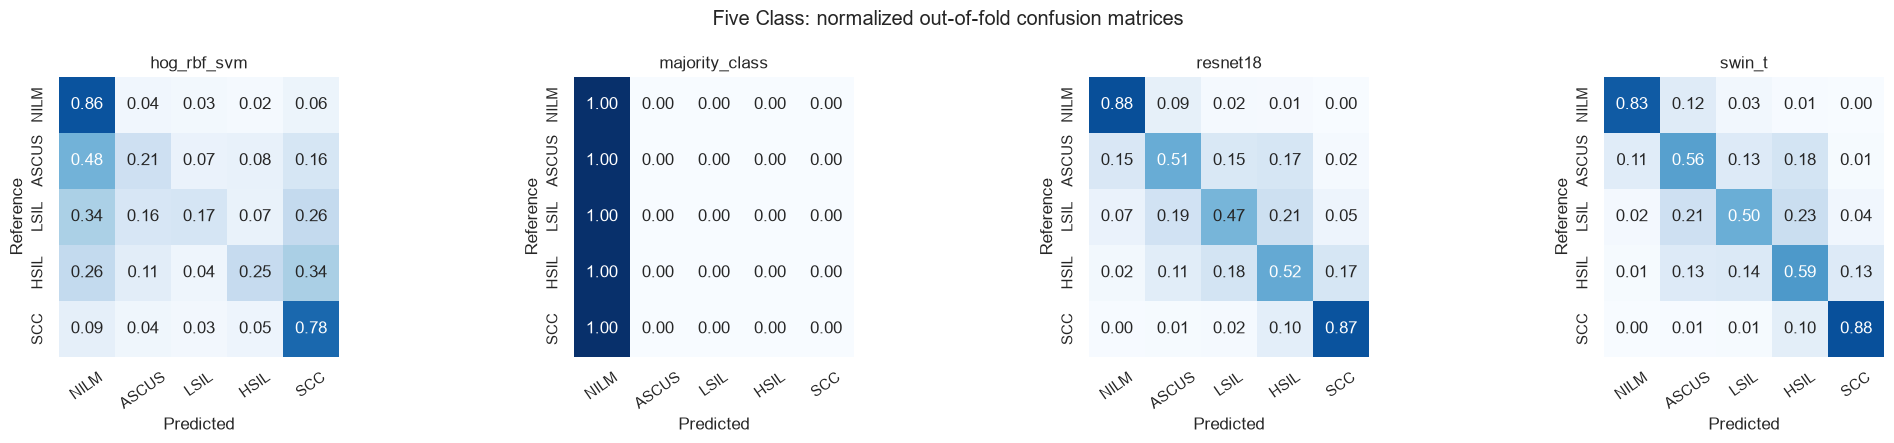

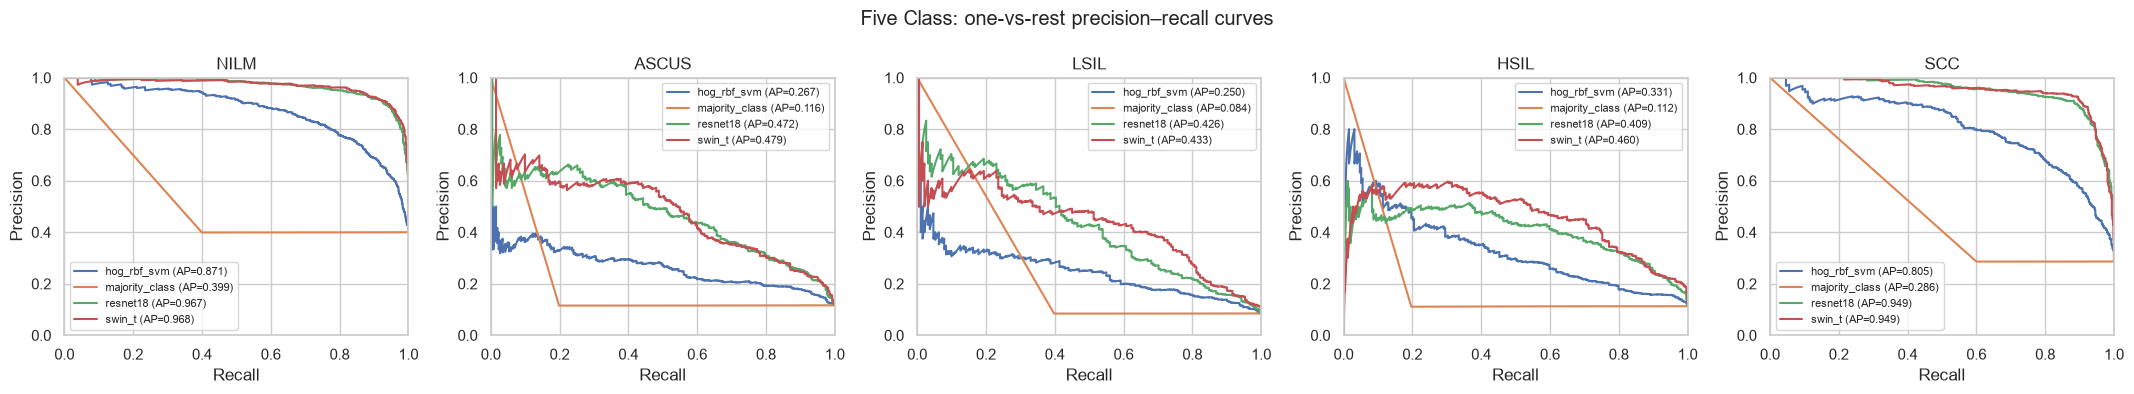

In [11]:
for task in CONFIG.tasks:
    classes = THREE_CLASSES if task == "three_class" else FIVE_CLASSES
    model_names = sorted(predictions.query("task == @task").model.unique())
    fig, axes = plt.subplots(1, len(model_names), figsize=(5.2 * len(model_names), 4.5), squeeze=False)
    for axis, model_name in zip(axes[0], model_names):
        frame = predictions.query("task == @task and model == @model_name")
        cm = confusion_matrix(frame.y_true, frame.y_pred, labels=np.arange(len(classes)), normalize="true")
        sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, ax=axis,
                    xticklabels=classes, yticklabels=classes, cbar=False)
        axis.set(title=model_name, xlabel="Predicted", ylabel="Reference")
        axis.tick_params(axis="x", rotation=35)
    fig.suptitle(f"{task.replace('_', ' ').title()}: normalized out-of-fold confusion matrices")
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / f"Figure_2_{task}_confusion_matrices.png", dpi=300, bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(1, len(classes), figsize=(4.3 * len(classes), 4), squeeze=False)
    for class_index, (axis, class_name) in enumerate(zip(axes[0], classes)):
        for model_name in model_names:
            frame = predictions.query("task == @task and model == @model_name")
            y_binary = (frame.y_true.to_numpy() == class_index).astype(int)
            probability = frame[f"prob_{class_name}"].to_numpy()
            precision, recall, _ = precision_recall_curve(y_binary, probability)
            ap = average_precision_score(y_binary, probability)
            axis.plot(recall, precision, label=f"{model_name} (AP={ap:.3f})")
        axis.set(title=class_name, xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
        axis.legend(fontsize=8)
    fig.suptitle(f"{task.replace('_', ' ').title()}: one-vs-rest precision–recall curves")
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / f"Figure_3_{task}_precision_recall.png", dpi=300, bbox_inches="tight")
    plt.show()


In [ ]:
# Compact forest plot for the two primary metrics.
plot_data = summary_metrics.query(
    "cohort == 'full_release' and metric in ['balanced_accuracy', 'macro_f1']"
).copy()
plot_data["label"] = plot_data.task.str.replace("_", " ").str.title() + " · " + plot_data.model

fig, axes = plt.subplots(1, 2, figsize=(13, max(4.5, 0.42 * plot_data.label.nunique())))
for axis, metric in zip(axes, ["balanced_accuracy", "macro_f1"]):
    frame = plot_data[plot_data.metric == metric].sort_values(["task", "estimate"])
    y = np.arange(len(frame))
    axis.errorbar(
        frame.estimate, y,
        xerr=[frame.estimate - frame.ci95_low, frame.ci95_high - frame.estimate],
        fmt="o", capsize=3, color="#3548b5"
    )
    axis.set_yticks(y, frame.label)
    axis.set_xlim(0, 1)
    axis.set_xlabel("Estimate with 95% stratified image-bootstrap CI")
    axis.set_title(metric.replace("_", " ").title())
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "Figure_4_primary_metrics_forest_plot.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
run_manifest = {
    "created_at_unix": time.time(),
    "run_mode": RUN_MODE,
    "dataset": {
        "name": "PapSmear-BD_Zenodo_v1.0.0",
        "images": len(manifest),
        "data_manifest_sha256": sha256_file(DATASET_ROOT / "metadata.csv"),
    },
    "split": {
        "strategy": "deterministic five-fold stratified image-level cross-validation",
        "folds": CONFIG.folds,
        "stratification_label": "five-class released diagnosis",
        "shuffle": True,
        "random_seed": CONFIG.seed,
        "manifest_sha256": split_hash,
    },
    "tasks": {
        "three_class": {
            "NILM": ["NILM"],
            "LOW_GRADE": ["ASCUS", "LSIL"],
            "HIGH_GRADE": ["HSIL", "SCC"],
        },
        "five_class": FIVE_CLASSES,
    },
    "models": ["majority_class"]
    + (["hog_rbf_svm"] if CONFIG.run_svm else [])
    + list(CONFIG.deep_models),
    "primary_metrics": ["balanced_accuracy", "macro_f1"],
    "uncertainty": (
        f"{CONFIG.bootstrap_replicates}-replicate image bootstrap stratified by true class"
    ),
    "config": asdict(CONFIG),
    "software": {
        "python": sys.version,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "scikit_learn": sklearn.__version__,
        "scikit_image": skimage.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}
with (OUTPUT_ROOT / "run_manifest.json").open("w", encoding="utf-8") as handle:
    json.dump(run_manifest, handle, indent=2)

print("Output files:")
for path in sorted(OUTPUT_ROOT.glob("*")):
    print("-", path.name)

